# 수험번호를 반드시 입력하세요!

**문제를 시작하기 전에, 바로 아래 셀의 `student_id`에 본인의 수험번호를 입력하고 실행하세요.**

예: `student_id = '001234'` — 앞자리 0도 포함하여 따옴표 안에 입력하세요.


In [1]:
# 본인의 수험번호를 따옴표 안에 입력하세요. 예: '001234'
student_id = '000000'
if not student_id or not student_id.isascii() or not student_id.isdigit():
    raise ValueError('수험번호를 숫자로만 입력하세요. 앞자리 0도 그대로 적습니다.')
print('수험번호:', student_id)


수험번호: 000000


## 코드 작성 안내
- 답안 작성과 관련 있는 셀은 앞쪽에 `답안 작성 셀`로 시작하는 마크다운 셀이 있습니다.
- 수정이 불가한 셀에는 `# 수정 금지`로 표시가 되어있습니다. 해당 주석이 있는 셀의 코드는 절대 수정하지 마세요.
- 수정 가능한 셀은 `# 수정 가능`으로 표시가 되어있습니다. 다만 셀 안에서 함수명 등 변경하면 안되는 부분도 있으니, 그런 경우 해당 셀 혹은 문항의 안내를 참고하세요.

# 문제 2-2. 이미지 분류 모델 개선 (Kaggle, 예측)

> **[예측 문제]** 공식 샘플의 형식·제약을 그대로 따르고 데이터와 함정만 바꾼 연습 문제입니다. 실제 시험 문제가 아닙니다.

상품 이미지로 TinyViT를 학습하고, 테스트 이미지의 클래스를 예측하세요. 가장 높은 accuracy가 목표입니다.\
학습 데이터는 20개 클래스에 각각 400개씩, 총 8,000개입니다(적은 클래스는 같은 이미지 반복).\
**검증과 테스트 데이터의 절반은 판매자 앱 업로드 사진**(작게·치우쳐·기울어·어둡게·흑백)입니다.\
**# 수정 가능** 표시가 있는 증강, 모델 구조, 하이퍼파라미터, 학습 셀을 수정하세요.\
데이터, 클래스 번호, 이미지 크기(높이 80 × 너비 60)는 유지하세요.\
노트북과 같은 폴더의 `test.csv`(`id,answer`)를 추론 셀이 채웁니다. 완료된 `test.csv`를 이름 변경 없이 제출하세요.

참고 자료는 [오프라인 문서 목록](docs/index.html)에서 볼 수 있습니다. `docs` 폴더를 함께 보관하세요.


## 환경 설정

아래 셀은 가상환경이 설정되어 있으며 커널이 해당 가상환경으로 잡혀 있는지를 체크합니다.
꼭 실행해서 확인 후에 진행하세요. 오류가 발생하면 이 폴더의 README.md를 참고해 환경을 다시 확인하세요.
특히 VS Code, PyCharm 환경에서 Jupyter Notebook 커널을 꼭 확인하세요.


In [2]:
# 수정 금지
# 먼저 실행해 현재 커널과 GPU를 확인하세요.

import sys
from pathlib import Path

print('Python:', sys.version.split()[0])
print('현재 커널:', sys.executable)
print('작업 폴더:', Path.cwd())

expected_env = Path.cwd() / '.venv'
if Path(sys.prefix).resolve() != expected_env.resolve():
    raise RuntimeError(
        f"{expected_env / 'Scripts' / 'python.exe'}를 노트북 커널로 선택하세요. "
        '환경이 없다면 setup.cmd를 실행하고, 작업 폴더도 노트북이 있는 폴더로 맞추세요.'
    )

try:
    import torch
    import torchvision
    import timm
except ImportError as error:
    raise RuntimeError("필요한 패키지를 불러오지 못했습니다. setup.cmd를 실행한 뒤 커널을 다시 시작하세요.") from error

print('PyTorch:', torch.__version__, '/ torchvision:', torchvision.__version__, '/ timm:', timm.__version__)
print('PyTorch CUDA:', torch.version.cuda)
if not torch.cuda.is_available():
    raise RuntimeError("CUDA GPU를 사용할 수 없습니다. 커널, NVIDIA 드라이버, CUDA용 PyTorch 설치를 확인하세요.")

print('GPU:', torch.cuda.get_device_name(0))
torch.zeros(1, device='cuda').sum().item()
print('커널과 GPU 확인 완료. 다음 셀로 진행하세요.')


Python: 3.12.10
현재 커널: C:\Users\SSAFY\Desktop\AI_Lv3_sample_solution\.venv\Scripts\python.exe
작업 폴더: C:\Users\SSAFY\Desktop\AI_Lv3_final_predict


C:\Users\SSAFY\Desktop\AI_Lv3_sample_solution\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch: 2.11.0+cu128 / torchvision: 0.26.0+cu128 / timm: 1.0.31
PyTorch CUDA: 12.8
GPU: NVIDIA GeForce RTX 5060 Ti
커널과 GPU 확인 완료. 다음 셀로 진행하세요.


In [3]:
# 수정 금지

import csv
import json
import time

import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
from sklearn.metrics import accuracy_score

torch.manual_seed(42)
device = 'cuda'


## 데이터 불러오기
`prepared.npz`의 학습 8,000장(클래스당 400장)과 검증 2,000장(절반은 앱 업로드 사진)을 읽습니다.\
테스트 이미지는 `data/f2_2_kaggle/test/<id>`에 있습니다.

In [4]:
# 수정 금지

data_dir = Path('data/f2_2_kaggle')
data_path = data_dir / 'prepared.npz'

In [5]:
# 수정 금지

with (data_dir / 'classes.json').open(encoding='utf-8') as file:
    class_names = json.load(file)
num_classes = len(class_names)

with np.load(data_path, allow_pickle=False) as data:
    train_images = data['train_images']
    train_labels = data['train_labels'].reshape(-1)
    val_images = data['val_images']
    val_labels = data['val_labels'].reshape(-1)

print('학습:', len(train_images), '검증:', len(val_images))
print('클래스:', num_classes, '/ 이미지 크기:', train_images[0].shape)

학습: 8000 검증: 2000
클래스: 20 / 이미지 크기: (80, 60, 3)


# **답안 작성 셀 - 학습용 증강**

`train_transform`에 증강을 추가하세요. 이미지를 읽을 때마다 변환이 적용됩니다.
검증·테스트용 `eval_transform`은 유지하세요.

참고: [RandomHorizontalFlip](docs/pages/docs.pytorch.org/vision_stable_generated_torchvision.transforms.RandomHorizontalFlip--b82b1b19a0d6.html),
[ColorJitter](docs/pages/docs.pytorch.org/vision_stable_generated_torchvision.transforms.ColorJitter--3d1cbb994bdb.html),
[Normalize](docs/pages/docs.pytorch.org/vision_stable_generated_torchvision.transforms.Normalize--38363001ace9.html)


In [6]:
# 수정 금지

mean = (0.485, 0.456, 0.406)
std = (0.229, 0.224, 0.225)
eval_transform = T.Compose([
    T.ToTensor(),
    T.Normalize(mean, std),
])


In [7]:
# 수정 가능

train_transform = T.Compose([
    T.ToPILImage(),
    T.ToTensor(),
    T.Normalize(mean, std),
])


In [8]:
# 수정 가능

class FashionDataset(Dataset):
    def __init__(self, images, labels, transform):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        image = self.transform(self.images[index])
        return image, int(self.labels[index])


In [9]:
# 수정 금지

with Path('test.csv').open(encoding='utf-8', newline='') as file:
    test_ids = [row['id'] for row in csv.DictReader(file)]


class FashionTestDataset(Dataset):
    def __init__(self, image_dir, ids, transform):
        self.image_dir = image_dir
        self.ids = ids
        self.transform = transform

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, index):
        sample_id = self.ids[index]
        with Image.open(self.image_dir / sample_id) as image:
            image = self.transform(image.convert('RGB'))
        return image, sample_id


print('테스트 이미지:', len(test_ids))


테스트 이미지: 2000


# **답안 작성 셀 - TinyViT와 사전학습 가중치**

TinyViT 5M의 구조를 아래 셀에 제공합니다. \
필요한 경우 모델 구조를 수정해도 됩니다. 같은 폴더의
`tiny_vit_5m_224.dist_in22k_ft_in1k.safetensors`를 읽고 전체 파라미터를 학습합니다.\
사전학습 가중치와 입력 크기는 유지하세요.

모델 구조 수정은 반드시 수행할 필요는 없습니다

P1_1, P1_2, P2_1, P2_2는 노트북과 같은 폴더의 `tiny_vit_5m_224.dist_in22k_ft_in1k.safetensors` 파일을 함께 사용합니다. 사전학습 가중치를 다운로드할 필요가 없습니다. 

참고: [TinyViT 논문](docs/pages/arxiv.org/abs_2207.10666--75d1c6c4be04.html),
[Microsoft 공식 구현](docs/pages/github.com/microsoft_Cream_blob_main_TinyViT_models_tiny_vit.py--7c367b0b0023.html),
[사용한 사전학습 모델](docs/pages/huggingface.co/timm_tiny_vit_5m_224.dist_in22k_ft_in1k--7b8991aa746a.html)


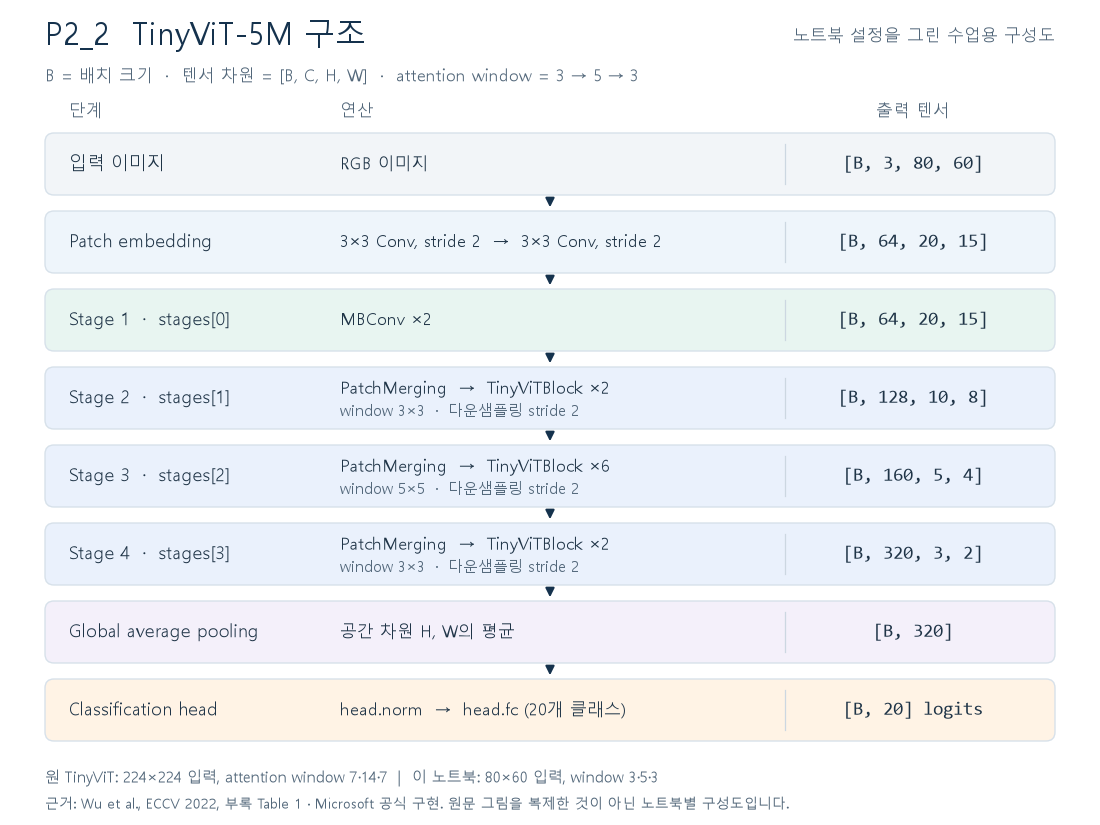

이 노트북의 구조를 그린 그림입니다. \
원 논문의 구조 설정은 [부록 Table 1](docs/pages/www.ecva.net/`papers_eccv_2022_papers_ECCV_papers_136810068-supp.pdf--b108d5257b8f.html)에서 확인할 수 있습니다.\
이 과제에서는 입력을 80×60으로, attention window 크기를 3·5·3으로 조정했습니다.


In [10]:
# 수정 가능

class ConvNorm(nn.Sequential):
    """Conv2d와 BatchNorm2d로 구성한 기본 블록."""
    def __init__(self, in_channels, out_channels, kernel_size=1,
                 stride=1, padding=0, groups=1, bn_weight=1.0):
        super().__init__()
        self.conv = nn.Conv2d(
            in_channels, out_channels, kernel_size,
            stride=stride, padding=padding, groups=groups, bias=False,
        )
        self.bn = nn.BatchNorm2d(out_channels)
        nn.init.constant_(self.bn.weight, bn_weight)
        nn.init.zeros_(self.bn.bias)


class PatchEmbed(nn.Module):
    """원본 입력을 특징 맵으로 변환: [B, 3, 80, 60] → [B, 64, 20, 15]."""
    def __init__(self, dim=64):
        super().__init__()
        self.conv1 = ConvNorm(3, dim // 2, 3, stride=2, padding=1)
        self.act = nn.GELU()
        self.conv2 = ConvNorm(dim // 2, dim, 3, stride=2, padding=1)

    def forward(self, x):
        x = self.conv1(x)
        x = self.act(x)
        return self.conv2(x)

In [11]:
# 수정 가능

class MBConv(nn.Module):
    """Stage 0: 채널 확장 → depthwise convolution → 채널 축소."""
    def __init__(self, dim, expand_ratio=4):
        super().__init__()
        hidden_dim = dim * expand_ratio
        self.conv1 = ConvNorm(dim, hidden_dim)
        self.act1 = nn.GELU()
        self.conv2 = ConvNorm(hidden_dim, hidden_dim, 3,
                              padding=1, groups=hidden_dim)
        self.act2 = nn.GELU()
        self.conv3 = ConvNorm(hidden_dim, dim, bn_weight=0.0)
        self.act3 = nn.GELU()

    def forward(self, x):
        shortcut = x
        x = self.act1(self.conv1(x))
        x = self.act2(self.conv2(x))
        x = self.conv3(x)
        return self.act3(x + shortcut)


class ConvStage(nn.Module):
    def __init__(self, dim, depth):
        super().__init__()
        self.blocks = nn.Sequential(*[MBConv(dim) for _ in range(depth)])

    def forward(self, x):
        return self.blocks(x)


class PatchMerging(nn.Module):
    """해상도를 절반으로 줄이고 다음 stage의 채널 수로 변환."""
    def __init__(self, in_dim, out_dim):
        super().__init__()
        self.conv1 = ConvNorm(in_dim, out_dim)
        self.act1 = nn.GELU()
        self.conv2 = ConvNorm(out_dim, out_dim, 3, stride=2,
                              padding=1, groups=out_dim)
        self.act2 = nn.GELU()
        self.conv3 = ConvNorm(out_dim, out_dim)

    def forward(self, x):
        x = self.act1(self.conv1(x))
        x = self.act2(self.conv2(x))
        return self.conv3(x)

In [12]:
# 수정 가능

class NormMLP(nn.Module):
    def __init__(self, dim, mlp_ratio=4):
        super().__init__()
        self.norm = nn.LayerNorm(dim)
        self.fc1 = nn.Linear(dim, dim * mlp_ratio)
        self.act = nn.GELU()
        self.fc2 = nn.Linear(dim * mlp_ratio, dim)

    def forward(self, x):
        x = self.norm(x)
        x = self.fc1(x)
        x = self.act(x)
        return self.fc2(x)


class WindowAttention(nn.Module):
    """작은 window 안에서 수행하는 multi-head self-attention."""
    def __init__(self, dim, num_heads, window_size):
        super().__init__()
        self.num_heads = num_heads
        self.head_dim = dim // num_heads
        self.scale = self.head_dim ** -0.5
        self.norm = nn.LayerNorm(dim)
        self.qkv = nn.Linear(dim, dim * 3)
        self.proj = nn.Linear(dim, dim)

        # window 내 두 위치 사이의 상대 거리에 따른 학습 가능한 bias
        coords = torch.stack(torch.meshgrid(
            torch.arange(window_size), torch.arange(window_size), indexing="ij"
        )).flatten(1)
        offsets = (coords[:, :, None] - coords[:, None, :]).abs()
        bias_indices = offsets[0] * window_size + offsets[1]
        self.register_buffer("attention_bias_idxs", bias_indices, persistent=False)
        self.attention_biases = nn.Parameter(
            torch.zeros(num_heads, window_size * window_size)
        )

    def forward(self, x):
        batch_size, num_tokens, dim = x.shape
        x = self.norm(x)

        # 체크포인트의 QKV 배치 순서: 각 head 안에 Q, K, V가 들어 있습니다.
        qkv = self.qkv(x).reshape(
            batch_size, num_tokens, self.num_heads, 3 * self.head_dim
        )
        qkv = qkv.transpose(1, 2)
        q, k, v = qkv.chunk(3, dim=-1)

        attention = (q * self.scale) @ k.transpose(-2, -1)
        bias = self.attention_biases[:, self.attention_bias_idxs]
        attention = (attention + bias.unsqueeze(0)).softmax(dim=-1)
        x = attention @ v
        x = x.transpose(1, 2).reshape(batch_size, num_tokens, dim)
        return self.proj(x)

In [13]:
# 수정 가능

class TinyViTBlock(nn.Module):
    """윈도 어텐션 → 지역 합성곱 → 다층 퍼셉트론."""
    def __init__(self, dim, num_heads, window_size):
        super().__init__()
        self.window_size = window_size
        self.attn = WindowAttention(dim, num_heads, window_size)
        self.local_conv = ConvNorm(dim, dim, 3, padding=1, groups=dim)
        self.mlp = NormMLP(dim)

    def forward(self, x):
        # 이 블록 안에서는 [B, H, W, C] 순서로 처리합니다.
        batch_size, height, width, channels = x.shape
        shortcut = x
        window = self.window_size

        # 해상도가 window 크기의 배수가 아닐 때 오른쪽·아래쪽에 padding
        pad_h = (window - height % window) % window
        pad_w = (window - width % window) % window
        x = F.pad(x, (0, 0, 0, pad_w, 0, pad_h))
        padded_h, padded_w = height + pad_h, width + pad_w
        num_h, num_w = padded_h // window, padded_w // window

        # 이미지 → 여러 window
        x = x.reshape(batch_size, num_h, window, num_w, window, channels)
        x = x.transpose(2, 3).reshape(-1, window * window, channels)
        x = self.attn(x)

        # 여러 window → 이미지
        x = x.reshape(batch_size, num_h, num_w, window, window, channels)
        x = x.transpose(2, 3).reshape(batch_size, padded_h, padded_w, channels)
        x = x[:, :height, :width, :].contiguous()
        x = shortcut + x

        x = x.permute(0, 3, 1, 2)
        x = self.local_conv(x)
        x = x.flatten(2).transpose(1, 2)
        x = x + self.mlp(x)
        return x.reshape(batch_size, height, width, channels)


class TinyViTStage(nn.Module):
    def __init__(self, in_dim, out_dim, depth, num_heads, window_size):
        super().__init__()
        self.downsample = PatchMerging(in_dim, out_dim)
        self.blocks = nn.Sequential(*[
            TinyViTBlock(out_dim, num_heads, window_size) for _ in range(depth)
        ])

    def forward(self, x):
        x = self.downsample(x)
        x = x.permute(0, 2, 3, 1)
        x = self.blocks(x)
        return x.permute(0, 3, 1, 2)


In [14]:
# 수정 가능

from safetensors.torch import load_file

class ClassifierHead(nn.Module):
    def __init__(self, dim, num_classes):
        super().__init__()
        self.norm = nn.LayerNorm(dim, eps=1e-5)
        self.fc = nn.Linear(dim, num_classes)

    def forward(self, x):
        x = x.mean(dim=(2, 3))
        x = self.norm(x)
        return self.fc(x)


def load_pretrained_weights(model):
    """제공된 로컬 가중치를 읽고 상대 위치 bias만 입력 크기에 맞게 보간합니다."""
    path = Path('tiny_vit_5m_224.dist_in22k_ft_in1k.safetensors')
    if not path.is_file():
        raise FileNotFoundError(
            f'사전학습 가중치 파일을 찾을 수 없습니다: {path.resolve()}\n'
            '제공된 가중치 파일을 노트북과 같은 폴더에 두고, 작업 폴더를 해당 폴더로 맞추세요.'
        )
    weights = load_file(str(path))
    target = model.state_dict()
    for name, value in weights.items():
        if name.endswith('attention_biases') and value.shape != target[name].shape:
            num_heads, length = value.shape
            old_window = int(length ** 0.5)
            new_window = int(target[name].shape[1] ** 0.5)
            weights[name] = F.interpolate(
                value.float().reshape(1, num_heads, old_window, old_window),
                size=(new_window, new_window),
                mode='bicubic', antialias=True,
            ).reshape(num_heads, new_window * new_window)
    model.load_state_dict(weights, strict=True)


In [15]:
# 수정 가능

class FashionModel(nn.Module):
    """원본 크기의 이미지에서 전체 파라미터를 미세조정하는 TinyViT 5M입니다."""
    def __init__(self):
        super().__init__()
        self.patch_embed = PatchEmbed(dim=64)
        self.stages = nn.Sequential(
            ConvStage(dim=64, depth=2),
            TinyViTStage(64, 128, depth=2, num_heads=4, window_size=3),
            TinyViTStage(128, 160, depth=6, num_heads=5, window_size=5),
            TinyViTStage(160, 320, depth=2, num_heads=10, window_size=3),
        )
        self.head = ClassifierHead(320, num_classes=1000)
        load_pretrained_weights(self)
        self.head.fc = nn.Linear(320, num_classes)

    def forward(self, x):
        x = self.patch_embed(x)
        x = self.stages[0](x)
        x = self.stages[1](x)
        x = self.stages[2](x)
        x = self.stages[3](x)
        x = x.mean(dim=(2, 3))
        x = self.head.norm(x)
        return self.head.fc(x)


# **답안 작성 셀 - 학습 설정**

아래 설정을 바꾼 뒤 DataLoader와 학습 셀을 다시 실행하세요.\
학습할 때마다 같은 사전학습 가중치에서 시작하며, 매 epoch의 검증 Accuracy을 비교합니다.

참고: [Adam](docs/pages/docs.pytorch.org/docs_stable_generated_torch.optim.Adam--6d92a2e47a7f.html)


In [16]:
# 수정 가능

batch_size = 64
learning_rate = 0.0003
epochs = 20


In [17]:
# 수정 금지
output_dir = Path('outputs')
output_dir.mkdir(exist_ok=True)
checkpoint = output_dir / f'F2_2_{student_id}.pt'
history_path = output_dir / f'F2_2_{student_id}_history.csv'
submission_path = Path('test.csv')

In [18]:
# 수정 금지

train_dataset = FashionDataset(train_images, train_labels, train_transform)
val_dataset = FashionDataset(val_images, val_labels, eval_transform)
test_dataset = FashionTestDataset(data_dir / 'test', test_ids, eval_transform)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=0)


# **답안 작성 셀 - 학습과 검증**

Cross Entropy로 학습하며 매 epoch의 학습·검증 Loss와 검증 Accuracy을 출력합니다.\
검증 Accuracy이 가장 높을 때의 가중치를 `outputs/P2_2_<수험번호>.pt`에 저장합니다.\
학습 기록은 `outputs/P2_2_<수험번호>_history.csv`에 저장합니다.

참고: [PyTorch 학습·검증 루프](docs/pages/docs.pytorch.org/tutorials_beginner_basics_optimization_tutorial--ad1a8b720acf.html)


In [19]:
# 수정 가능

def train_one_epoch(model, loader, optimizer, loss_fn):
    model.train()
    total_loss = 0
    sample_count = 0
    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)
        optimizer.zero_grad()
        logits = model(images)
        loss = loss_fn(logits, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(labels)
        sample_count += len(labels)
    return total_loss / sample_count


def evaluate(model, loader, loss_fn):
    model.eval()
    total_loss = 0
    predictions, targets = [], []
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)
            logits = model(images)
            total_loss += loss_fn(logits, labels).item() * len(labels)
            predictions.extend(logits.argmax(1).cpu().tolist())
            targets.extend(labels.cpu().tolist())
    accuracy = accuracy_score(targets, predictions)
    return total_loss / len(targets), accuracy


In [20]:
# 수정 가능

torch.manual_seed(42)
model = FashionModel().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
loss_fn = nn.CrossEntropyLoss()
best_accuracy = -1
history = []
started = time.perf_counter()

for epoch in range(epochs):
    train_loss = train_one_epoch(model, train_loader, optimizer, loss_fn)
    val_loss, val_accuracy = evaluate(model, val_loader, loss_fn)
    history.append({
        'epoch': epoch + 1,
        'train_loss': train_loss,
        'val_loss': val_loss,
        'val_accuracy': val_accuracy,
    })
    if val_accuracy > best_accuracy:
        best_accuracy = val_accuracy
        torch.save(model.state_dict(), checkpoint)
    print(f'{epoch + 1:2d}/{epochs}  학습 Loss: {train_loss:.4f}  '
          f'검증 Loss: {val_loss:.4f}  검증 Accuracy: {val_accuracy:.4f}')

with history_path.open('w', encoding='utf-8', newline='') as file:
    writer = csv.DictWriter(file, fieldnames=['epoch', 'train_loss', 'val_loss', 'val_accuracy'])
    writer.writeheader()
    writer.writerows(history)
print(f'최고 검증 Accuracy: {best_accuracy:.4f} / 학습 시간: {time.perf_counter() - started:.1f}초')
print('체크포인트:', checkpoint)


 1/20  학습 Loss: 1.0967  검증 Loss: 1.3288  검증 Accuracy: 0.6135


 2/20  학습 Loss: 0.2797  검증 Loss: 1.3288  검증 Accuracy: 0.6230


 3/20  학습 Loss: 0.1666  검증 Loss: 1.0726  검증 Accuracy: 0.6930


 4/20  학습 Loss: 0.1087  검증 Loss: 1.2378  검증 Accuracy: 0.6610


 5/20  학습 Loss: 0.0866  검증 Loss: 1.3030  검증 Accuracy: 0.6520


 6/20  학습 Loss: 0.0542  검증 Loss: 1.2948  검증 Accuracy: 0.6725


... (10 outputs left out)

17/20  학습 Loss: 0.0240  검증 Loss: 1.2440  검증 Accuracy: 0.7160


18/20  학습 Loss: 0.0151  검증 Loss: 1.2844  검증 Accuracy: 0.7060


19/20  학습 Loss: 0.0153  검증 Loss: 1.3912  검증 Accuracy: 0.6885


20/20  학습 Loss: 0.0136  검증 Loss: 1.3264  검증 Accuracy: 0.7090
최고 검증 Accuracy: 0.7160 / 학습 시간: 224.5초
체크포인트: outputs\F2_2_000000.pt


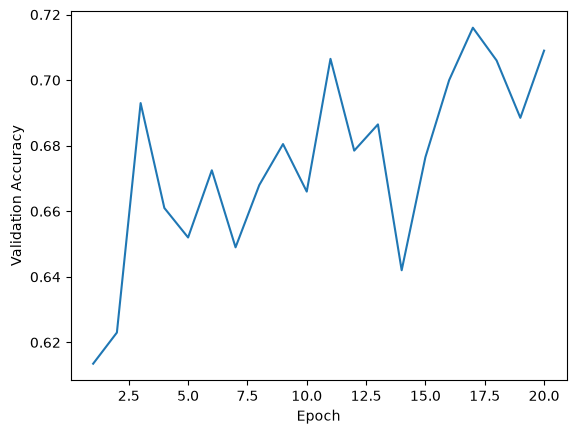

In [21]:
# 수정 가능

plt.plot([row['epoch'] for row in history], [row['val_accuracy'] for row in history])
plt.xlabel('Epoch')
plt.ylabel('Validation Accuracy')
plt.show()


## 테스트 추론과 Kaggle 제출

가장 좋은 검증 가중치를 다시 불러와 테스트 DataLoader로 예측합니다.\
노트북과 같은 폴더의 `test.csv`에서 읽은 ID 순서를 유지하고, `answer` 열을 예측값으로 채워 같은 파일에 저장합니다.\
`answer`는 `classes.json` 순서의 정수 클래스 번호(0~19)입니다.\
완성된 **`test.csv`를 그대로 Kaggle에 제출**하세요. 파일명에 수험번호를 붙이지 않습니다.\
추론 셀을 다시 실행하면 `answer`가 새 예측값으로 갱신됩니다.

참고: [모델 가중치 저장과 불러오기](docs/pages/docs.pytorch.org/tutorials_beginner_basics_saveloadrun_tutorial--102f53b27159.html)


In [22]:
# 수정 금지

model.load_state_dict(torch.load(checkpoint, map_location=device, weights_only=True))
model.eval()
predicted_ids, predictions = [], []
with torch.no_grad():
    for images, ids in test_loader:
        logits = model(images.to(device))
        predictions.extend(logits.argmax(dim=1).cpu().tolist())
        predicted_ids.extend(ids)

with submission_path.open('w', encoding='utf-8', newline='') as file:
    writer = csv.writer(file)
    writer.writerow(['id', 'answer'])
    writer.writerows(zip(predicted_ids, predictions))
print(f'제출 파일: {submission_path} / {len(predictions)}개 예측')


제출 파일: test.csv / 2000개 예측
